# 05. מימוש אלגוריתמי סיווג צמתים וניסוי חוזר

**????.** ???? ???? ??? ? ?'??? ????? ? ????? ?????

**מטרה.** מגדירה baselines, מאפייני גרף/שכנים/קהילה, רגרסיה לוגיסטית וכיוון סף ללא leakage.

**מקום בתהליך.** מחברת 5 מתוך 9 בסדרת המחקר. יש להריץ את המחברות לפי הסדר המופיע ב-`notebooks/README.md`; עם זאת, קוד האתחול מאתר את שורש הפרויקט גם בהרצה עצמאית.

**קלטים.** הגרף, התוויות והקהילות; seeds קבועים לחלוקות stratified.

**פלטים.** תוצאות חמש ריצות, ממוצעים, סטיות תקן, מדדי סיווג ותרשימי השוואה.

**קשר לשאלות המחקר.** עונה ישירות על RQ1 ומכינה baseline הוגן להשוואות RQ2.

**עקרונות שחזוריות.** `random_state` קבוע היכן שנדרש, כל התוצאות נשמרות תחת `outputs/`, מאפיינים מבוססי תווית נבנים מתוויות train בלבד, וכל קוד המקור הרלוונטי מוצג בתאי קוד עם נתיב ושורות מקור.

## אתחול בטוח ובלתי תלוי בתיקיית ההרצה

התא הבא מאתר את שורש הריפוזיטורי דרך `requirements.txt`, עובר אליו, מוסיף את `src` לנתיב הייבוא ומגדיר תצוגה עקבית. שינוי `__name__` מונע מבלוקי `if __name__ == "__main__"` שהועתקו כלשונם לפעול לפני תא ההרצה המתועד שלהם. הפלט הצפוי הוא הנתיב המוחלט של הפרויקט.

In [1]:
from pathlib import Path
import os
import sys
import warnings

def _find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / "data").exists():
            return candidate.resolve()
    raise FileNotFoundError("לא נמצא שורש הפרויקט המכיל requirements.txt ו-data/")

ROOT = _find_project_root(Path.cwd())
os.chdir(ROOT)
SRC_DIR = ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
os.environ.setdefault("PYTHONHASHSEED", "0")
warnings.filterwarnings("ignore", category=FutureWarning)
__name__ = "research_notebook_05"
print(f"Project root: {ROOT}")

Project root: C:\Users\Jimi\Desktop\github-social-network


**פלט ומשמעות.** הופעת הנתיב `github-social-network` מאשרת שכל הנתיבים היחסיים בהמשך יופנו לפרויקט הנכון. אם התא נכשל, אין להמשיך: הכשל מצביע על הרצה מחוץ לעץ הפרויקט או על עותק חסר.

## מתודולוגיית הסיווג

ארבע רמות נבדקות: Majority (רף imbalance), Neighbor Majority (אות מקומי), Logistic Regression על תכונות גרף, ו-Logistic Regression עם תכונות קהילה. Logistic Regression ממדלת `P(y=1|x)=σ(wᵀx+b)` וממזערת log-loss עם רגולריזציה; היא פרשנית ומהירה יחסית אך מניחה גבול ליניארי במרחב התכונות. כל תוצאה היא ממוצע וסטיית תקן על seeds 42, 7, 21, 84, 123. תוויות test אינן נכנסות לתכונות, ו-threshold נבחר על validation פנימי בלבד.

## קוד המקור: `src/modeling.py`

פרוטוקול הסיווג: חלוקות, baselines, feature engineering, Logistic Regression, metrics וכיוון סף.

לפני טעינת הקטעים נגדיר עבורם `__file__` וירטואלי התואם למיקומם המקורי. הדבר משמר את לוגיקת חישוב `PROJECT_DIR` בלי לשנות שורה בקוד המקור. SHA-256 של המקור: `162ca18beb26e5881adea2d1382952b505963d34acf67df9546ca5f0374dee28`.

התא הבא מכין את הקשר הנתיבים עבור קובץ המקור. הוא אינו משנה את הקובץ; הפלט הצפוי הוא נתיב המקור שממנו הועתק הקוד.

In [2]:
__file__ = str(ROOT / 'src/modeling.py')
print(f"Source context: {__file__}")

Source context: C:\Users\Jimi\Desktop\github-social-network\src\modeling.py


**פלט ומשמעות.** הנתיב המודפס מאפשר לבקר שהקבועים בקוד יחושבו ביחס לריפוזיטורי הנוכחי בלבד.

### modeling.py, שורות 1-30: ייבואים, קבועים והגדרות מודול

**מה ומדוע.** הבלוק מרכז את התלויות, הקבועים והנחות ברירת המחדל של המודול; בלעדיו הפונקציות הבאות אינן עצמאיות.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [3]:
# -*- coding: utf-8 -*-
from typing import Dict, Iterable, Sequence, Tuple

import networkx as nx
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from community_analysis import (
    add_community_features,
    detect_louvain_communities,
    summarize_communities,
)


COMMUNITY_ID_COLUMN = "community_id"




**פלט ומשמעות.** בלוק `ייבואים, קבועים והגדרות מודול` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 31-53: `prepare_train_test_split`

**מה ומדוע.** חלוקה stratified שומרת יחס מחלקות ומקבעת seed להשוואה הוגנת. תיעוד המקור מסביר: Create a stratified train/test split over labeled node IDs.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [4]:
def prepare_train_test_split(
    labels_df: pd.DataFrame,
    test_size: float = 0.3,
    random_state: int = 42,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Create a stratified train/test split over labeled node IDs."""
    if "id" not in labels_df.columns or "label" not in labels_df.columns:
        raise ValueError("labels_df must contain 'id' and 'label' columns.")

    nodes = labels_df["id"].to_numpy(dtype=np.int64)
    labels = labels_df["label"].to_numpy(dtype=np.int64)

    train_nodes, test_nodes, y_train, y_test = train_test_split(
        nodes,
        labels,
        test_size=test_size,
        random_state=random_state,
        stratify=labels,
    )

    return train_nodes, test_nodes, y_train, y_test




**פלט ומשמעות.** בלוק ``prepare_train_test_split`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 54-74: `majority_class_baseline`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי. תיעוד המקור מסביר: Predict the train-set majority class for all test nodes. Returns: y_pred: hard predictions y_score: constant ML probability (train positive-class prior)

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [5]:
def majority_class_baseline(y_train: Iterable[int], y_test: Iterable[int]) -> Tuple[np.ndarray, np.ndarray]:
    """
    Predict the train-set majority class for all test nodes.

    Returns:
        y_pred: hard predictions
        y_score: constant ML probability (train positive-class prior)
    """
    y_train_arr = np.asarray(list(y_train), dtype=np.int64)
    y_test_arr = np.asarray(list(y_test), dtype=np.int64)

    class_counts = np.bincount(y_train_arr, minlength=2)
    majority_label = int(np.argmax(class_counts))
    ml_prior = float(np.mean(y_train_arr))

    y_pred = np.full(shape=y_test_arr.shape, fill_value=majority_label, dtype=np.int64)
    y_score = np.full(shape=y_test_arr.shape, fill_value=ml_prior, dtype=np.float64)

    return y_pred, y_score




**פלט ומשמעות.** בלוק ``majority_class_baseline`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 75-128: `neighbor_majority_classifier`

**מה ומדוע.** baseline מקומי לפי שכני train בלבד; צומת ללא שכנים מתויגים חוזר למחלקת הרוב. תיעוד המקור מסביר: Predict each test node from the majority label among its train-labeled neighbors. The ML score is the fraction of known ML neighbors. If no known neighbors exist, prediction falls back to default_label and score to train ML prior.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [6]:
def neighbor_majority_classifier(
    G: nx.Graph,
    labels_dict: Dict[int, int],
    train_nodes: Iterable[int],
    test_nodes: Iterable[int],
    default_label: int,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Predict each test node from the majority label among its train-labeled neighbors.

    The ML score is the fraction of known ML neighbors.
    If no known neighbors exist, prediction falls back to default_label and score to train ML prior.
    """
    train_set = {int(node) for node in train_nodes}
    test_list = [int(node) for node in test_nodes]
    train_label_dict = {node: int(labels_dict[node]) for node in train_set if node in labels_dict}
    train_ml_prior = float(np.mean(list(train_label_dict.values()))) if train_label_dict else 0.5

    y_pred = []
    y_score = []

    for node in test_list:
        known_web = 0
        known_ml = 0

        if node in G:
            for neighbor in G.neighbors(node):
                if neighbor not in train_set:
                    continue
                neighbor_label = train_label_dict.get(int(neighbor))
                if neighbor_label == 0:
                    known_web += 1
                elif neighbor_label == 1:
                    known_ml += 1

        known_total = known_web + known_ml
        if known_total == 0:
            pred_label = int(default_label)
            ml_score = train_ml_prior
        else:
            ml_score = known_ml / known_total
            if known_ml > known_web:
                pred_label = 1
            elif known_web > known_ml:
                pred_label = 0
            else:
                pred_label = int(default_label)

        y_pred.append(pred_label)
        y_score.append(ml_score)

    return np.asarray(y_pred, dtype=np.int64), np.asarray(y_score, dtype=np.float64)




**פלט ומשמעות.** בלוק ``neighbor_majority_classifier`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 129-221: `extract_graph_neighbor_features`

**מה ומדוע.** מחשב degree, clustering, PageRank ומאפייני שכנים בלי לגעת בתוויות test. תיעוד המקור מסביר: Build graph-only features for given nodes. Label-based neighborhood features use only labels of train_nodes.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [7]:
def extract_graph_neighbor_features(
    G: nx.Graph,
    labels_dict: Dict[int, int],
    train_nodes: Iterable[int],
    nodes: Iterable[int],
) -> pd.DataFrame:
    """
    Build graph-only features for given nodes.

    Label-based neighborhood features use only labels of train_nodes.
    """
    train_set = {int(node) for node in train_nodes}
    train_label_dict = {node: int(labels_dict[node]) for node in train_set if node in labels_dict}
    nodes_list = [int(node) for node in nodes]

    # Cache expensive structure-only scores to speed repeated experiments.
    if "_pagerank_cache" not in G.graph:
        G.graph["_pagerank_cache"] = nx.pagerank(G)
    if "_clustering_cache" not in G.graph:
        G.graph["_clustering_cache"] = nx.clustering(G)
    if "_core_number_cache" not in G.graph:
        G.graph["_core_number_cache"] = nx.core_number(G)
    
    # --- Fast sample-based approximation of Betweenness Centrality ---
    if "_approx_betweenness_cache" not in G.graph:
        G.graph["_approx_betweenness_cache"] = nx.betweenness_centrality(G, k=100, seed=42)

    # HITS hub and authority scores coincide on an undirected graph.  Keep one
    # score only so the feature matrix does not contain a known duplicate.
    if "_hits_cache" not in G.graph:
        try:
            hubs, _ = nx.hits(G, max_iter=800)
        except nx.PowerIterationFailedConvergence:
            hubs = {}
        G.graph["_hits_cache"] = True
        G.graph["_hubs_cache"] = hubs
        
    if "_triangles_cache" not in G.graph:
        G.graph["_triangles_cache"] = nx.triangles(G)

    pagerank_scores = G.graph["_pagerank_cache"]
    clustering_scores = G.graph["_clustering_cache"]
    core_numbers = G.graph["_core_number_cache"]
    approx_betweenness = G.graph["_approx_betweenness_cache"]
    hubs_scores = G.graph["_hubs_cache"]
    triangles_counts = G.graph["_triangles_cache"]

    rows = []
    for node in nodes_list:
        degree = int(G.degree(node)) if node in G else 0

        known_web = 0
        known_ml = 0
        if node in G:
            for neighbor in G.neighbors(node):
                if neighbor not in train_set:
                    continue
                neighbor_label = train_label_dict.get(int(neighbor))
                if neighbor_label == 0:
                    known_web += 1
                elif neighbor_label == 1:
                    known_ml += 1

        known_neighbors_count = known_web + known_ml
        if known_neighbors_count > 0:
            ml_neighbor_ratio = known_ml / known_neighbors_count
            web_neighbor_ratio = known_web / known_neighbors_count
        else:
            ml_neighbor_ratio = 0.0
            web_neighbor_ratio = 0.0

        rows.append(
            {
                "node_id": node,
                "degree": degree,
                "known_neighbors_count": known_neighbors_count,
                "known_web_neighbors": known_web,
                "known_ml_neighbors": known_ml,
                "ml_neighbor_ratio": ml_neighbor_ratio,
                "web_neighbor_ratio": web_neighbor_ratio,
                "neighbor_label_gap": known_ml - known_web,
                "clustering_coefficient": float(clustering_scores.get(node, 0.0)),
                "pagerank": float(pagerank_scores.get(node, 0.0)),
                "core_number": int(core_numbers.get(node, 0)),
                "approx_betweenness": float(approx_betweenness.get(node, 0.0)),
                "hits_hub_score": float(hubs_scores.get(node, 0.0)),
                "triangles": int(triangles_counts.get(node, 0)),
            }
        )

    return pd.DataFrame(rows)




**פלט ומשמעות.** בלוק ``extract_graph_neighbor_features`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 222-230: `_merge_node_feature_frames`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי. תיעוד המקור מסביר: Merge two feature frames on node_id with a clean column order.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [8]:
def _merge_node_feature_frames(
    base_features_df: pd.DataFrame,
    extra_features_df: pd.DataFrame,
) -> pd.DataFrame:
    """Merge two feature frames on node_id with a clean column order."""
    merged = base_features_df.merge(extra_features_df, on="node_id", how="inner")
    return merged




**פלט ומשמעות.** בלוק ``_merge_node_feature_frames`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 231-262: `_prepare_feature_matrix`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי. תיעוד המקור מסביר: Remove non-feature identifiers prior to model fitting. Currently we drop: - node_id community_id is categorical. It is one-hot encoded instead of being interpreted as an ordinal numeric value.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [9]:
def _prepare_feature_matrix(
    feature_df: pd.DataFrame,
    fit_columns: Sequence[str] | None = None,
) -> pd.DataFrame:
    """
    Remove non-feature identifiers prior to model fitting.

    Currently we drop:
    - node_id

    community_id is categorical. It is one-hot encoded instead of being
    interpreted as an ordinal numeric value.
    """
    x_df = feature_df.copy()
    if "node_id" in x_df.columns:
        x_df = x_df.drop(columns=["node_id"])

    if COMMUNITY_ID_COLUMN in x_df.columns:
        x_df[COMMUNITY_ID_COLUMN] = x_df[COMMUNITY_ID_COLUMN].astype("category")
        x_df = pd.get_dummies(
            x_df,
            columns=[COMMUNITY_ID_COLUMN],
            prefix="community",
            dtype=float,
        )

    if fit_columns is not None:
        x_df = x_df.reindex(columns=list(fit_columns), fill_value=0.0)

    return x_df




**פלט ומשמעות.** בלוק ``_prepare_feature_matrix`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 263-287: `train_logistic_regression_graph_features`

**מה ומדוע.** Pipeline של קידוד/סטנדרטיזציה ורגרסיה לוגיסטית; האימון תלוי במספר הדוגמאות, התכונות ואיטרציות האופטימיזציה. תיעוד המקור מסביר: Train Logistic Regression over network-only features via a scaling pipeline.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [10]:
def train_logistic_regression_graph_features(
    X_train: pd.DataFrame,
    y_train: Iterable[int],
    X_test: pd.DataFrame,
) -> Tuple[Pipeline, np.ndarray, np.ndarray]:
    """Train Logistic Regression over network-only features via a scaling pipeline."""
    x_train_df = _prepare_feature_matrix(X_train)
    x_test_df = _prepare_feature_matrix(X_test, fit_columns=x_train_df.columns)

    model = Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            # --- class_weight="balanced" to handle the class imbalance ---
            ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
        ]
    )
    model.fit(x_train_df, np.asarray(list(y_train), dtype=np.int64))
    model.feature_columns_ = list(x_train_df.columns)

    y_pred = model.predict(x_test_df)
    y_score = model.predict_proba(x_test_df)[:, 1]

    return model, y_pred.astype(np.int64), y_score.astype(np.float64)




**פלט ומשמעות.** בלוק ``train_logistic_regression_graph_features`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 288-300: `predict_logistic_regression_graph_features`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי. תיעוד המקור מסביר: Predict ML probabilities with the same feature columns used during training.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [11]:
def predict_logistic_regression_graph_features(
    model: Pipeline,
    X: pd.DataFrame,
) -> np.ndarray:
    """Predict ML probabilities with the same feature columns used during training."""
    feature_columns = getattr(model, "feature_columns_", None)
    if feature_columns is None:
        raise ValueError("Model is missing feature_columns_. Train it with train_logistic_regression_graph_features.")

    x_df = _prepare_feature_matrix(X, fit_columns=feature_columns)
    return model.predict_proba(x_df)[:, 1].astype(np.float64)




**פלט ומשמעות.** בלוק ``predict_logistic_regression_graph_features`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 301-337: `evaluate_predictions`

**מה ומדוע.** מחשב Accuracy, Balanced Accuracy, Precision, Recall, F1, Macro/Weighted F1, ROC-AUC ומטריצת בלבול. תיעוד המקור מסביר: Compute classification metrics and confusion-matrix entries.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [12]:
def evaluate_predictions(
    y_true: Iterable[int],
    y_pred: Iterable[int],
    y_score: Iterable[float] | None = None,
) -> Dict[str, float]:
    """Compute classification metrics and confusion-matrix entries."""
    y_true_arr = np.asarray(list(y_true), dtype=np.int64)
    y_pred_arr = np.asarray(list(y_pred), dtype=np.int64)

    cm = confusion_matrix(y_true_arr, y_pred_arr, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    metrics = {
        "accuracy": float(accuracy_score(y_true_arr, y_pred_arr)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true_arr, y_pred_arr)),
        "precision": float(precision_score(y_true_arr, y_pred_arr, zero_division=0)),
        "recall": float(recall_score(y_true_arr, y_pred_arr, zero_division=0)),
        "f1": float(f1_score(y_true_arr, y_pred_arr, zero_division=0)),
        "macro_f1": float(f1_score(y_true_arr, y_pred_arr, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true_arr, y_pred_arr, average="weighted", zero_division=0)),
        "roc_auc": float("nan"),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }

    if y_score is not None:
        y_score_arr = np.asarray(list(y_score), dtype=np.float64)
        try:
            metrics["roc_auc"] = float(roc_auc_score(y_true_arr, y_score_arr))
        except ValueError:
            metrics["roc_auc"] = float("nan")

    return metrics




**פלט ומשמעות.** בלוק ``evaluate_predictions`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 338-388: `evaluate_thresholds`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי. תיעוד המקור מסביר: Evaluate binary predictions across multiple probability thresholds.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [13]:
def evaluate_thresholds(
    y_true: Iterable[int],
    y_score: Iterable[float],
    thresholds: Sequence[float] | None = None,
) -> pd.DataFrame:
    """Evaluate binary predictions across multiple probability thresholds."""
    y_true_arr = np.asarray(list(y_true), dtype=np.int64)
    y_score_arr = np.asarray(list(y_score), dtype=np.float64)

    if y_true_arr.shape[0] != y_score_arr.shape[0]:
        raise ValueError("y_true and y_score must have the same length.")

    if thresholds is None:
        threshold_values = np.round(np.arange(0.05, 0.951, 0.05), 2)
    else:
        threshold_values = np.asarray(list(thresholds), dtype=np.float64)
        if threshold_values.size == 0:
            raise ValueError("thresholds must not be empty.")

    rows = []
    for threshold in threshold_values:
        threshold_float = float(threshold)
        if threshold_float < 0.0 or threshold_float > 1.0:
            raise ValueError("All thresholds must be in [0.0, 1.0].")

        y_pred_arr = (y_score_arr >= threshold_float).astype(np.int64)
        cm = confusion_matrix(y_true_arr, y_pred_arr, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        specificity = float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0

        rows.append(
            {
                "threshold": threshold_float,
                "accuracy": float(accuracy_score(y_true_arr, y_pred_arr)),
                "balanced_accuracy": float(balanced_accuracy_score(y_true_arr, y_pred_arr)),
                "precision": float(precision_score(y_true_arr, y_pred_arr, zero_division=0)),
                "recall": float(recall_score(y_true_arr, y_pred_arr, zero_division=0)),
                "f1": float(f1_score(y_true_arr, y_pred_arr, zero_division=0)),
                "macro_f1": float(f1_score(y_true_arr, y_pred_arr, average="macro", zero_division=0)),
                "weighted_f1": float(f1_score(y_true_arr, y_pred_arr, average="weighted", zero_division=0)),
                "specificity": specificity,
                "tn": int(tn),
                "fp": int(fp),
                "fn": int(fn),
                "tp": int(tp),
            }
        )

    return pd.DataFrame(rows).sort_values("threshold").reset_index(drop=True)




**פלט ומשמעות.** בלוק ``evaluate_thresholds`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 389-409: `select_best_threshold`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי. תיעוד המקור מסביר: Return the threshold row with the highest value for the selected metric.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [14]:
def select_best_threshold(
    threshold_results_df: pd.DataFrame,
    metric: str = "f1",
) -> Tuple[float, pd.Series]:
    """Return the threshold row with the highest value for the selected metric."""
    if threshold_results_df.empty:
        raise ValueError("threshold_results_df must not be empty.")
    if "threshold" not in threshold_results_df.columns:
        raise ValueError("threshold_results_df must include a 'threshold' column.")
    if metric not in threshold_results_df.columns:
        raise ValueError(f"metric '{metric}' was not found in threshold_results_df.")

    ranking_df = threshold_results_df.sort_values(
        by=[metric, "threshold"],
        ascending=[False, True],
    )
    best_row = ranking_df.iloc[0].copy()
    best_threshold = float(best_row["threshold"])
    return best_threshold, best_row




**פלט ומשמעות.** בלוק ``select_best_threshold`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 410-532: `run_repeated_threshold_tuning`

**מה ומדוע.** בוחר סף רק על validation פנימי ומעריך פעם אחת על test, לכן אינו מכוונן על נתוני הבחינה. תיעוד המקור מסביר: Repeat threshold tuning across multiple train/test splits without test leakage. Per split: 1) Split labeled nodes into train/test 2) Split train into train_inner/validation 3) Train Graph+Community Logistic Regression on train_inner only 4) Choose threshold on validation only 5) Evaluate on test using threshold=0.5 and the tuned threshold

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [15]:
def run_repeated_threshold_tuning(
    G: nx.Graph,
    labels_df: pd.DataFrame,
    partition: Dict[int, int],
    community_summary_df: pd.DataFrame,
    random_states: Sequence[int] = (42, 7, 21, 84, 123),
    test_size: float = 0.3,
    validation_size: float = 0.2,
    threshold_metric: str = "f1",
) -> pd.DataFrame:
    """
    Repeat threshold tuning across multiple train/test splits without test leakage.

    Per split:
    1) Split labeled nodes into train/test
    2) Split train into train_inner/validation
    3) Train Graph+Community Logistic Regression on train_inner only
    4) Choose threshold on validation only
    5) Evaluate on test using threshold=0.5 and the tuned threshold
    """
    if "id" not in labels_df.columns or "label" not in labels_df.columns:
        raise ValueError("labels_df must contain 'id' and 'label' columns.")
    if validation_size <= 0 or validation_size >= 1:
        raise ValueError("validation_size must be in (0, 1).")

    labels_dict = dict(zip(labels_df["id"].astype(int), labels_df["label"].astype(int)))
    results_rows = []

    for run_idx, random_state in enumerate(list(random_states), start=1):
        train_nodes, test_nodes, y_train, y_test = prepare_train_test_split(
            labels_df=labels_df,
            test_size=test_size,
            random_state=int(random_state),
        )

        train_inner_nodes, val_nodes, y_train_inner, y_val = train_test_split(
            train_nodes,
            y_train,
            test_size=validation_size,
            random_state=int(random_state),
            stratify=y_train,
        )

        train_inner_nodes = np.asarray(train_inner_nodes, dtype=np.int64)
        val_nodes = np.asarray(val_nodes, dtype=np.int64)
        y_train_inner = np.asarray(y_train_inner, dtype=np.int64)
        y_val = np.asarray(y_val, dtype=np.int64)

        nodes_for_features = list(train_inner_nodes) + list(val_nodes) + list(test_nodes)

        graph_features_df = extract_graph_neighbor_features(
            G=G,
            labels_dict=labels_dict,
            train_nodes=train_inner_nodes,
            nodes=nodes_for_features,
        ).drop_duplicates(subset=["node_id"])

        community_features_df = add_community_features(
            G=G,
            labels_dict=labels_dict,
            train_nodes=train_inner_nodes,
            nodes=nodes_for_features,
            partition=partition,
            community_summary_df=community_summary_df,
        ).drop_duplicates(subset=["node_id"])

        combined_features_df = _merge_node_feature_frames(graph_features_df, community_features_df)
        combined_features_indexed = combined_features_df.set_index("node_id")

        X_train_inner = combined_features_indexed.reindex(train_inner_nodes).reset_index()
        X_val = combined_features_indexed.reindex(val_nodes).reset_index()
        X_test = combined_features_indexed.reindex(test_nodes).reset_index()

        model, _, y_score_val = train_logistic_regression_graph_features(
            X_train=X_train_inner,
            y_train=y_train_inner,
            X_test=X_val,
        )

        threshold_results_df = evaluate_thresholds(y_true=y_val, y_score=y_score_val)
        tuned_threshold, _ = select_best_threshold(
            threshold_results_df=threshold_results_df,
            metric=threshold_metric,
        )

        y_score_test = predict_logistic_regression_graph_features(model, X_test)

        for evaluation_type, threshold in (
            ("default_threshold_0.5", 0.5),
            ("tuned_threshold_validation_f1", float(tuned_threshold)),
        ):
            y_pred_test = (y_score_test >= float(threshold)).astype(np.int64)
            metrics = evaluate_predictions(y_test, y_pred_test, y_score=y_score_test)

            tn = int(metrics["tn"])
            fp = int(metrics["fp"])
            specificity = float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0

            results_rows.append(
                {
                    "run": int(run_idx),
                    "random_state": int(random_state),
                    "selected_threshold": float(threshold),
                    "evaluation_type": evaluation_type,
                    "accuracy": float(metrics["accuracy"]),
                    "balanced_accuracy": float(metrics["balanced_accuracy"]),
                    "precision": float(metrics["precision"]),
                    "recall": float(metrics["recall"]),
                    "f1": float(metrics["f1"]),
                    "macro_f1": float(metrics["macro_f1"]),
                    "weighted_f1": float(metrics["weighted_f1"]),
                    "roc_auc": float(metrics["roc_auc"]),
                    "specificity": specificity,
                    "tn": tn,
                    "fp": fp,
                    "fn": int(metrics["fn"]),
                    "tp": int(metrics["tp"]),
                }
            )

    return pd.DataFrame(results_rows)




**פלט ומשמעות.** בלוק ``run_repeated_threshold_tuning`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 533-605: `summarize_threshold_tuning_results`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי. תיעוד המקור מסביר: Summarize repeated threshold-tuning results by evaluation type (mean/std).

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [16]:
def summarize_threshold_tuning_results(results_df: pd.DataFrame) -> pd.DataFrame:
    """Summarize repeated threshold-tuning results by evaluation type (mean/std)."""
    required_cols = {
        "evaluation_type",
        "selected_threshold",
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1",
        "macro_f1",
        "weighted_f1",
        "roc_auc",
        "specificity",
    }
    missing_cols = required_cols - set(results_df.columns)
    if missing_cols:
        raise ValueError(f"results_df is missing required columns: {sorted(missing_cols)}")

    summary_df = (
        results_df.groupby("evaluation_type", as_index=False)
        .agg(
            selected_threshold_mean=("selected_threshold", "mean"),
            selected_threshold_std=("selected_threshold", "std"),
            accuracy_mean=("accuracy", "mean"),
            accuracy_std=("accuracy", "std"),
            balanced_accuracy_mean=("balanced_accuracy", "mean"),
            balanced_accuracy_std=("balanced_accuracy", "std"),
            precision_mean=("precision", "mean"),
            precision_std=("precision", "std"),
            recall_mean=("recall", "mean"),
            recall_std=("recall", "std"),
            f1_mean=("f1", "mean"),
            f1_std=("f1", "std"),
            macro_f1_mean=("macro_f1", "mean"),
            macro_f1_std=("macro_f1", "std"),
            weighted_f1_mean=("weighted_f1", "mean"),
            weighted_f1_std=("weighted_f1", "std"),
            roc_auc_mean=("roc_auc", "mean"),
            roc_auc_std=("roc_auc", "std"),
            specificity_mean=("specificity", "mean"),
            specificity_std=("specificity", "std"),
        )
        .rename(
            columns={
                "evaluation_type": "Evaluation Type",
                "selected_threshold_mean": "Selected Threshold Mean",
                "selected_threshold_std": "Selected Threshold Std",
                "accuracy_mean": "Accuracy Mean",
                "accuracy_std": "Accuracy Std",
                "balanced_accuracy_mean": "Balanced Accuracy Mean",
                "balanced_accuracy_std": "Balanced Accuracy Std",
                "precision_mean": "Precision Mean",
                "precision_std": "Precision Std",
                "recall_mean": "Recall Mean",
                "recall_std": "Recall Std",
                "f1_mean": "F1 Mean",
                "f1_std": "F1 Std",
                "macro_f1_mean": "Macro F1 Mean",
                "macro_f1_std": "Macro F1 Std",
                "weighted_f1_mean": "Weighted F1 Mean",
                "weighted_f1_std": "Weighted F1 Std",
                "roc_auc_mean": "ROC-AUC Mean",
                "roc_auc_std": "ROC-AUC Std",
                "specificity_mean": "Specificity Mean",
                "specificity_std": "Specificity Std",
            }
        )
    )

    return summary_df




**פלט ומשמעות.** בלוק ``summarize_threshold_tuning_results`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 606-733: `run_repeated_experiments`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי. תיעוד המקור מסביר: Run repeated train/test experiments across multiple random splits. Models: - Majority Baseline - Neighbor Majority - Logistic Regression - Graph Features Only - Logistic Regression - Graph + Community Features

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [17]:
def run_repeated_experiments(
    G: nx.Graph,
    labels_df: pd.DataFrame,
    n_runs: int = 5,
    test_size: float = 0.3,
    random_states: Sequence[int] = (42, 7, 21, 84, 123),
) -> pd.DataFrame:
    """
    Run repeated train/test experiments across multiple random splits.

    Models:
    - Majority Baseline
    - Neighbor Majority
    - Logistic Regression - Graph Features Only
    - Logistic Regression - Graph + Community Features
    """
    if "id" not in labels_df.columns or "label" not in labels_df.columns:
        raise ValueError("labels_df must contain 'id' and 'label' columns.")
    if n_runs <= 0:
        raise ValueError("n_runs must be positive.")

    random_states = list(random_states)
    if len(random_states) < n_runs:
        raise ValueError("random_states must include at least n_runs values.")

    selected_states = random_states[:n_runs]
    labels_dict = dict(zip(labels_df["id"].astype(int), labels_df["label"].astype(int)))

    # Louvain depends only on graph structure, so we compute it once.
    partition, _ = detect_louvain_communities(G, random_state=42)
    community_summary_df = summarize_communities(G, labels_dict, partition)

    results_rows = []

    for run_idx, random_state in enumerate(selected_states, start=1):
        train_nodes, test_nodes, y_train, y_test = prepare_train_test_split(
            labels_df=labels_df,
            test_size=test_size,
            random_state=int(random_state),
        )
        default_label = int(pd.Series(y_train).mode().iloc[0])
        nodes_for_features = list(train_nodes) + list(test_nodes)

        # 1) Majority baseline
        y_pred_majority, y_score_majority = majority_class_baseline(y_train, y_test)
        metrics_majority = evaluate_predictions(y_test, y_pred_majority, y_score_majority)

        # 2) Neighbor majority
        y_pred_neighbor, y_score_neighbor = neighbor_majority_classifier(
            G=G,
            labels_dict=labels_dict,
            train_nodes=train_nodes,
            test_nodes=test_nodes,
            default_label=default_label,
        )
        metrics_neighbor = evaluate_predictions(y_test, y_pred_neighbor, y_score_neighbor)

        # 3) Logistic regression on graph-only features
        graph_features_df = extract_graph_neighbor_features(
            G=G,
            labels_dict=labels_dict,
            train_nodes=train_nodes,
            nodes=nodes_for_features,
        ).drop_duplicates(subset=["node_id"])
        graph_features_indexed = graph_features_df.set_index("node_id")

        X_train_graph = graph_features_indexed.reindex(train_nodes).reset_index()
        X_test_graph = graph_features_indexed.reindex(test_nodes).reset_index()

        _, y_pred_logreg_graph, y_score_logreg_graph = train_logistic_regression_graph_features(
            X_train=X_train_graph,
            y_train=y_train,
            X_test=X_test_graph,
        )
        metrics_logreg_graph = evaluate_predictions(y_test, y_pred_logreg_graph, y_score_logreg_graph)

        # 4) Logistic regression on graph + community features
        community_features_df = add_community_features(
            G=G,
            labels_dict=labels_dict,
            train_nodes=train_nodes,
            nodes=nodes_for_features,
            partition=partition,
            community_summary_df=community_summary_df,
        ).drop_duplicates(subset=["node_id"])

        combined_features_df = _merge_node_feature_frames(graph_features_df, community_features_df)
        combined_features_indexed = combined_features_df.set_index("node_id")

        X_train_combined = combined_features_indexed.reindex(train_nodes).reset_index()
        X_test_combined = combined_features_indexed.reindex(test_nodes).reset_index()

        _, y_pred_logreg_graph_comm, y_score_logreg_graph_comm = train_logistic_regression_graph_features(
            X_train=X_train_combined,
            y_train=y_train,
            X_test=X_test_combined,
        )
        metrics_logreg_graph_comm = evaluate_predictions(
            y_test,
            y_pred_logreg_graph_comm,
            y_score_logreg_graph_comm,
        )

        for model_name, metrics in (
            ("Majority Baseline", metrics_majority),
            ("Neighbor Majority", metrics_neighbor),
            ("Logistic Regression - Graph Features Only", metrics_logreg_graph),
            ("Logistic Regression - Graph + Community Features", metrics_logreg_graph_comm),
        ):
            results_rows.append(
                {
                    "run": run_idx,
                    "random_state": int(random_state),
                    "model": model_name,
                    "accuracy": metrics["accuracy"],
                    "balanced_accuracy": metrics["balanced_accuracy"],
                    "precision": metrics["precision"],
                    "recall": metrics["recall"],
                    "f1": metrics["f1"],
                    "macro_f1": metrics["macro_f1"],
                    "weighted_f1": metrics["weighted_f1"],
                    "roc_auc": metrics["roc_auc"],
                }
            )

    return pd.DataFrame(results_rows)




**פלט ומשמעות.** בלוק ``run_repeated_experiments`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 734-796: `summarize_repeated_results`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי. תיעוד המקור מסביר: Aggregate mean and standard deviation of metrics per model.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [18]:
def summarize_repeated_results(results_df: pd.DataFrame) -> pd.DataFrame:
    """Aggregate mean and standard deviation of metrics per model."""
    required_cols = {
        "model",
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1",
        "macro_f1",
        "weighted_f1",
        "roc_auc",
    }
    missing_cols = required_cols - set(results_df.columns)
    if missing_cols:
        raise ValueError(f"results_df is missing required columns: {sorted(missing_cols)}")

    summary_df = (
        results_df.groupby("model", as_index=False)
        .agg(
            accuracy_mean=("accuracy", "mean"),
            accuracy_std=("accuracy", "std"),
            balanced_accuracy_mean=("balanced_accuracy", "mean"),
            balanced_accuracy_std=("balanced_accuracy", "std"),
            precision_mean=("precision", "mean"),
            precision_std=("precision", "std"),
            recall_mean=("recall", "mean"),
            recall_std=("recall", "std"),
            f1_mean=("f1", "mean"),
            f1_std=("f1", "std"),
            macro_f1_mean=("macro_f1", "mean"),
            macro_f1_std=("macro_f1", "std"),
            weighted_f1_mean=("weighted_f1", "mean"),
            weighted_f1_std=("weighted_f1", "std"),
            roc_auc_mean=("roc_auc", "mean"),
            roc_auc_std=("roc_auc", "std"),
        )
        .rename(
            columns={
                "model": "Model",
                "accuracy_mean": "Accuracy Mean",
                "accuracy_std": "Accuracy Std",
                "balanced_accuracy_mean": "Balanced Accuracy Mean",
                "balanced_accuracy_std": "Balanced Accuracy Std",
                "precision_mean": "Precision Mean",
                "precision_std": "Precision Std",
                "recall_mean": "Recall Mean",
                "recall_std": "Recall Std",
                "f1_mean": "F1 Mean",
                "f1_std": "F1 Std",
                "macro_f1_mean": "Macro F1 Mean",
                "macro_f1_std": "Macro F1 Std",
                "weighted_f1_mean": "Weighted F1 Mean",
                "weighted_f1_std": "Weighted F1 Std",
                "roc_auc_mean": "ROC-AUC Mean",
                "roc_auc_std": "ROC-AUC Std",
            }
        )
    )

    return summary_df




**פלט ומשמעות.** בלוק ``summarize_repeated_results`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 797-819: `assign_degree_group`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי. תיעוד המקור מסביר: Assign each node to a predefined degree bucket.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [19]:
def assign_degree_group(G: nx.Graph, nodes: Iterable[int]) -> pd.DataFrame:
    """Assign each node to a predefined degree bucket."""
    rows = []
    for node in nodes:
        node_int = int(node)
        degree = int(G.degree(node_int)) if node_int in G else 0

        if degree <= 2:
            group = "degree_0_2"
        elif degree <= 5:
            group = "degree_3_5"
        elif degree <= 10:
            group = "degree_6_10"
        elif degree <= 30:
            group = "degree_11_30"
        else:
            group = "degree_31_plus"

        rows.append({"node_id": node_int, "degree": degree, "degree_group": group})

    return pd.DataFrame(rows)




**פלט ומשמעות.** בלוק ``assign_degree_group`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 820-881: `evaluate_by_degree_group`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי. תיעוד המקור מסביר: Evaluate classification performance across node degree groups.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [20]:
def evaluate_by_degree_group(
    G: nx.Graph,
    test_nodes: Iterable[int],
    y_true: Iterable[int],
    y_pred: Iterable[int],
) -> pd.DataFrame:
    """Evaluate classification performance across node degree groups."""
    ordered_groups = [
        "degree_0_2",
        "degree_3_5",
        "degree_6_10",
        "degree_11_30",
        "degree_31_plus",
    ]

    degree_df = assign_degree_group(G, test_nodes)
    eval_df = pd.DataFrame(
        {
            "node_id": [int(n) for n in test_nodes],
            "y_true": np.asarray(list(y_true), dtype=np.int64),
            "y_pred": np.asarray(list(y_pred), dtype=np.int64),
        }
    )
    merged_df = eval_df.merge(degree_df[["node_id", "degree_group"]], on="node_id", how="left")

    rows = []
    for group in ordered_groups:
        group_df = merged_df[merged_df["degree_group"] == group]
        count = int(len(group_df))

        if count == 0:
            rows.append(
                {
                    "degree_group": group,
                    "count": 0,
                    "accuracy": np.nan,
                    "balanced_accuracy": np.nan,
                    "precision": np.nan,
                    "recall": np.nan,
                    "f1": np.nan,
                }
            )
            continue

        metrics = evaluate_predictions(group_df["y_true"], group_df["y_pred"], y_score=None)
        rows.append(
            {
                "degree_group": group,
                "count": count,
                "accuracy": metrics["accuracy"],
                    "balanced_accuracy": metrics["balanced_accuracy"],
                    "precision": metrics["precision"],
                    "recall": metrics["recall"],
                    "f1": metrics["f1"],
                    "macro_f1": metrics["macro_f1"],
                    "weighted_f1": metrics["weighted_f1"],
                }
            )

    return pd.DataFrame(rows)




**פלט ומשמעות.** בלוק ``evaluate_by_degree_group`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 882-938: `evaluate_errors_by_community_purity`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי. תיעוד המקור מסביר: Summarize model error rate by community-purity buckets.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [21]:
def evaluate_errors_by_community_purity(
    test_nodes: Iterable[int],
    y_true: Iterable[int],
    y_pred: Iterable[int],
    partition: Dict[int, int],
    community_summary_df: pd.DataFrame,
) -> pd.DataFrame:
    """Summarize model error rate by community-purity buckets."""
    purity_map = dict(
        zip(
            community_summary_df["community_id"].astype(int),
            community_summary_df["purity"].astype(float),
        )
    )

    rows = []
    for node, true_label, pred_label in zip(test_nodes, y_true, y_pred):
        community_id = int(partition.get(int(node), -1))
        purity = float(purity_map.get(community_id, 0.0))
        if purity < 0.7:
            purity_group = "mixed_lt_0.70"
        elif purity < 0.85:
            purity_group = "medium_0.70_0.85"
        else:
            purity_group = "pure_0.85_plus"

        rows.append(
            {
                "node_id": int(node),
                "community_id": community_id,
                "community_purity": purity,
                "purity_group": purity_group,
                "y_true": int(true_label),
                "y_pred": int(pred_label),
                "is_error": int(true_label) != int(pred_label),
            }
        )

    details_df = pd.DataFrame(rows)
    ordered_groups = ["mixed_lt_0.70", "medium_0.70_0.85", "pure_0.85_plus"]
    summary_rows = []
    for group in ordered_groups:
        group_df = details_df[details_df["purity_group"] == group]
        count = int(len(group_df))
        errors = int(group_df["is_error"].sum()) if count else 0
        summary_rows.append(
            {
                "purity_group": group,
                "count": count,
                "errors": errors,
                "error_rate": float(errors / count) if count else np.nan,
            }
        )

    return pd.DataFrame(summary_rows)




**פלט ומשמעות.** בלוק ``evaluate_errors_by_community_purity`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### modeling.py, שורות 939-966: `summarize_error_types`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי. תיעוד המקור מסביר: Count correct and incorrect predictions by semantic class transition.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [22]:
def summarize_error_types(
    y_true: Iterable[int],
    y_pred: Iterable[int],
) -> pd.DataFrame:
    """Count correct and incorrect predictions by semantic class transition."""
    y_true_arr = np.asarray(list(y_true), dtype=np.int64)
    y_pred_arr = np.asarray(list(y_pred), dtype=np.int64)

    type_map = {
        (0, 0): "Correct Web",
        (1, 1): "Correct ML",
        (0, 1): "Web -> ML",
        (1, 0): "ML -> Web",
    }

    rows = []
    total = len(y_true_arr)
    for pair, label in type_map.items():
        count = int(np.sum((y_true_arr == pair[0]) & (y_pred_arr == pair[1])))
        rows.append(
            {
                "error_type": label,
                "count": count,
                "ratio": float(count / total) if total else 0.0,
            }
        )

    return pd.DataFrame(rows)


**פלט ומשמעות.** בלוק ``summarize_error_types`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

## קוד המקור: `src/run_classification.py`

הרצה חוזרת בחמישה seeds, אגרגציה ותרשימי ביצועים עבור RQ1.

לפני טעינת הקטעים נגדיר עבורם `__file__` וירטואלי התואם למיקומם המקורי. הדבר משמר את לוגיקת חישוב `PROJECT_DIR` בלי לשנות שורה בקוד המקור. SHA-256 של המקור: `c98dceee7d7ffe62af343fd3a2151138374c8bb4e3bcc266a9698ea17f7a5977`.

התא הבא מכין את הקשר הנתיבים עבור קובץ המקור. הוא אינו משנה את הקובץ; הפלט הצפוי הוא נתיב המקור שממנו הועתק הקוד.

In [23]:
__file__ = str(ROOT / 'src/run_classification.py')
print(f"Source context: {__file__}")

Source context: C:\Users\Jimi\Desktop\github-social-network\src\run_classification.py


**פלט ומשמעות.** הנתיב המודפס מאפשר לבקר שהקבועים בקוד יחושבו ביחס לריפוזיטורי הנוכחי בלבד.

### run_classification.py, שורות 1-47: ייבואים, קבועים והגדרות מודול

**מה ומדוע.** הבלוק מרכז את התלויות, הקבועים והנחות ברירת המחדל של המודול; בלעדיו הפונקציות הבאות אינן עצמאיות.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [24]:
# -*- coding: utf-8 -*-
"""Repeated leakage-safe node classification with course-covered features."""

from pathlib import Path
import sys

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SRC_DIR = Path(__file__).resolve().parent
PROJECT_DIR = SRC_DIR.parent
sys.path.insert(0, str(SRC_DIR))

from community_analysis import (
    detect_louvain_communities,
    summarize_communities,
)
from data_loader import load_dataset
from modeling import (
    run_repeated_experiments,
    run_repeated_threshold_tuning,
)


SEEDS = (42, 7, 21, 84, 123)
BASE_CLASSIFICATION_MODELS = (
    "Majority Baseline",
    "Neighbor Majority",
    "Logistic Regression - Graph Features Only",
    "Logistic Regression - Graph + Community Features",
)
METRICS = (
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
    "macro_f1",
    "weighted_f1",
    "roc_auc",
)




**פלט ומשמעות.** בלוק `ייבואים, קבועים והגדרות מודול` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### run_classification.py, שורות 48-59: `summarize_results`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי. תיעוד המקור מסביר: Return one auditable mean/std row per model.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [25]:
def summarize_results(results_df: pd.DataFrame) -> pd.DataFrame:
    """Return one auditable mean/std row per model."""
    summary = results_df.groupby("model", as_index=False)[list(METRICS)].agg(
        ["mean", "std"]
    )
    summary.columns = [
        "model" if column == ("model", "") else f"{column[0]}_{column[1]}"
        for column in summary.columns
    ]
    return summary.sort_values("roc_auc_mean").reset_index(drop=True)




**פלט ומשמעות.** בלוק ``summarize_results`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### run_classification.py, שורות 60-85: `summarize_thresholds`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי. תיעוד המקור מסביר: Summarize validation-only threshold selection across seeds.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [26]:
def summarize_thresholds(results_df: pd.DataFrame) -> pd.DataFrame:
    """Summarize validation-only threshold selection across seeds."""
    metrics = [
        "selected_threshold",
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1",
        "macro_f1",
        "weighted_f1",
        "roc_auc",
        "specificity",
    ]
    summary = results_df.groupby("evaluation_type", as_index=False)[metrics].agg(
        ["mean", "std"]
    )
    summary.columns = [
        "evaluation_type"
        if column == ("evaluation_type", "")
        else f"{column[0]}_{column[1]}"
        for column in summary.columns
    ]
    return summary




**פלט ומשמעות.** בלוק ``summarize_thresholds`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### run_classification.py, שורות 86-128: `_plot_models`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [27]:
def _plot_models(summary_df: pd.DataFrame, output_path: Path) -> None:
    order = list(BASE_CLASSIFICATION_MODELS)
    plot_df = summary_df.set_index("model").reindex(order).reset_index()
    labels = [
        "Majority",
        "Neighbor\nMajority",
        "Graph\nFeatures",
        "Graph +\nCommunity",
    ]
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
    for ax, metric, title in (
        (axes[0], "macro_f1", "Macro F1"),
        (axes[1], "roc_auc", "ROC-AUC"),
    ):
        means = plot_df[f"{metric}_mean"]
        stds = plot_df[f"{metric}_std"]
        bars = ax.bar(
            labels,
            means,
            yerr=stds,
            capsize=4,
            color=["#9A9A9A", "#6B86A8", "#315C8D", "#4F8A5B"],
        )
        for bar, value in zip(bars, means):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                value + 0.012,
                f"{value:.3f}",
                ha="center",
                fontsize=9,
            )
        ax.set_title(title)
        ax.set_ylim(0.35, 1.02)
        ax.grid(axis="y", alpha=0.25)
    fig.suptitle(
        "Leakage-safe node classification\n"
        "Mean and standard deviation across five stratified splits"
    )
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.close(fig)




**פלט ומשמעות.** בלוק ``_plot_models`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### run_classification.py, שורות 129-159: `_plot_thresholds`

**מה ומדוע.** הבלוק מגדיר יחידת חישוב חוזרת בצנרת ומפריד בין לוגיקה לבין תזמור הניסוי.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [28]:
def _plot_thresholds(summary_df: pd.DataFrame, output_path: Path) -> None:
    order = ["default_threshold_0.5", "tuned_threshold_validation_f1"]
    plot_df = summary_df.set_index("evaluation_type").reindex(order)
    metrics = ["precision_mean", "recall_mean", "f1_mean"]
    labels = ["Precision", "Recall", "F1"]
    x = np.arange(len(metrics))
    width = 0.36
    fig, ax = plt.subplots(figsize=(8.5, 5))
    for offset, policy, color, name in (
        (-width / 2, order[0], "#7F8C8D", "Threshold 0.5"),
        (width / 2, order[1], "#315C8D", "Validation-tuned threshold"),
    ):
        ax.bar(
            x + offset,
            [plot_df.loc[policy, metric] for metric in metrics],
            width,
            color=color,
            label=name,
        )
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(0.5, 0.9)
    ax.set_ylabel("Mean test score")
    ax.set_title("Threshold selection uses validation data only")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.close(fig)




**פלט ומשמעות.** בלוק ``_plot_thresholds`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### run_classification.py, שורות 160-219: `main`

**מה ומדוע.** פונקציית התזמור של הקובץ. היא מוגדרת כאן אך אינה מופעלת אוטומטית; תא הרצה מפורש בהמשך מפעיל אותה ושומר פלטים.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** הגדרה בזיכרון ללא פלט חזותי; התוצאה תופיע כאשר הפונקציה תיקרא בתא הניסוי.

In [29]:
def main() -> None:
    data_dir = PROJECT_DIR / "data"
    tables_dir = PROJECT_DIR / "outputs" / "tables"
    figures_dir = PROJECT_DIR / "outputs" / "figures"
    tables_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)

    G, _, labels_df, labels_dict = load_dataset(data_dir)
    results_df = run_repeated_experiments(
        G,
        labels_df,
        n_runs=len(SEEDS),
        test_size=0.30,
        random_states=SEEDS,
    )
    unexpected = set(results_df["model"]) - set(BASE_CLASSIFICATION_MODELS)
    missing = set(BASE_CLASSIFICATION_MODELS) - set(results_df["model"])
    if unexpected or missing:
        raise AssertionError(
            f"Model mismatch: unexpected={sorted(unexpected)}, missing={sorted(missing)}"
        )
    summary_df = summarize_results(results_df)

    partition, _ = detect_louvain_communities(G, random_state=42)
    community_df = summarize_communities(G, labels_dict, partition)
    threshold_df = run_repeated_threshold_tuning(
        G,
        labels_df,
        partition,
        community_df,
        random_states=SEEDS,
        test_size=0.30,
        validation_size=0.20,
        threshold_metric="f1",
    )
    threshold_summary_df = summarize_thresholds(threshold_df)

    results_df.to_csv(
        tables_dir / "classification_results.csv", index=False
    )
    summary_df.to_csv(
        tables_dir / "classification_summary.csv", index=False
    )
    threshold_df.to_csv(
        tables_dir / "threshold_tuning_results.csv", index=False
    )
    threshold_summary_df.to_csv(
        tables_dir / "threshold_tuning_summary.csv", index=False
    )

    _plot_models(
        summary_df, figures_dir / "classification_comparison.png"
    )
    _plot_thresholds(
        threshold_summary_df, figures_dir / "threshold_tradeoff.png"
    )
    print(summary_df.to_string(index=False))
    print(threshold_summary_df.to_string(index=False))




**פלט ומשמעות.** בלוק ``main`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

### run_classification.py, שורות 220-221: `__main__ guard`

**מה ומדוע.** זהו שער ההרצה המקורי של קובץ CLI. במחברת הוא נשמר כלשונו, אך אינו מופעל כי `__name__` הוגדר כשם מחברת; ההרצה נעשית בתא מפורש ומתועד.

**שיטה/אלגוריתם.** הקוד נשמר בדיוק לפי המקור; ההסבר האלגוריתמי המלא ניתן בפרק המתודולוגי של המחברת.

**פלט צפוי.** אין פלט, משום ששער ה-CLI מושבת בכוונה בסביבת המחברת.

In [30]:
if __name__ == "__main__":
    main()


**פלט ומשמעות.** בלוק ``__main__ guard`` נטען בהצלחה. היעדר פלט הוא תקין עבור הגדרה; המשמעות המחקרית שלו נבחנת בתאי ההרצה והטבלאות שבהמשך, ולא מעצם הגדרת הפונקציה.

## הרצת השלב

**מה הקוד מבצע.** מריץ ארבעה מודלים על חמש חלוקות stratified ומבצע ניסוי threshold נוסף עם validation.

**מדוע נחוץ.** הגדרת פונקציות בלבד אינה מייצרת ראיות. התא מפעיל את אותו entry point של קובץ המקור ומחדש את הטבלאות/התרשימים בפועל.

**פלט צפוי.** 20 שורות תוצאות בסיס, 10 שורות threshold, שתי טבלאות סיכום ושני תרשימים.

In [31]:
_run_classification_main = main
_run_classification_main()

                                           model  accuracy_mean  accuracy_std  balanced_accuracy_mean  balanced_accuracy_std  precision_mean  precision_std  recall_mean  recall_std  f1_mean   f1_std  macro_f1_mean  macro_f1_std  weighted_f1_mean  weighted_f1_std  roc_auc_mean  roc_auc_std
                               Majority Baseline       0.741645      0.000000                0.500000               0.000000        0.000000       0.000000     0.000000    0.000000 0.000000 0.000000       0.425830      0.000000          0.631629         0.000000      0.500000     0.000000
                               Neighbor Majority       0.818780      0.003222                0.674080               0.005216        0.831198       0.012751     0.374675    0.009899 0.516468 0.010741       0.702481      0.006256          0.792379         0.004110      0.785099     0.005350
       Logistic Regression - Graph Features Only       0.803572      0.004287                0.759211               0.005618      

**פלט ומשמעות.** הודעות ההתקדמות שמעל מתעדות שהשלב רץ עד הסוף. הקבצים שנכתבו נטענים שוב בתאים הבאים, כך שממצא מספרי אינו נשען על טקסט מודפס בלבד.

### טבלה: `outputs/tables/classification_summary.csv`

ממוצעים וסטיות תקן לכל מודל. הקוד טוען מחדש את קובץ ה-CSV מהדיסק, ולכן התצוגה מאמתת גם שהפלט נשמר ולא רק חושב בזיכרון.

In [32]:
classification_summary = pd.read_csv(ROOT / 'outputs/tables/classification_summary.csv')
display(classification_summary[["model", "accuracy_mean", "balanced_accuracy_mean", "f1_mean", "macro_f1_mean", "roc_auc_mean"]].round(4))

,model,accuracy_mean,balanced_accuracy_mean,f1_mean,macro_f1_mean,roc_auc_mean
0,Majority Baseline,0.7416,0.5000,0.0000,0.4258,0.5000
1,Neighbor Majority,0.8188,0.6741,0.5165,0.7025,0.7851
2,Logistic Regression - Graph Features Only,0.8036,0.7592,0.6371,0.7512,0.8410
3,Logistic Regression - Graph + Community Features,0.8169,0.7870,0.6717,0.7724,0.8694


**פלט, ממצא ומשמעות.** Graph+Community הוא המודל הידני החזק ביותר: ROC-AUC≈0.869 ו-F1≈0.672. Majority משיג Accuracy גבוהה לכאורה אך F1=0 למחלקת ML, ולכן אינו פתרון.

### טבלה: `outputs/tables/threshold_tuning_summary.csv`

השוואת threshold=0.5 לסף שנבחר ב-validation. הקוד טוען מחדש את קובץ ה-CSV מהדיסק, ולכן התצוגה מאמתת גם שהפלט נשמר ולא רק חושב בזיכרון.

In [33]:
threshold_summary = pd.read_csv(ROOT / 'outputs/tables/threshold_tuning_summary.csv')
display(threshold_summary[["evaluation_type", "selected_threshold_mean", "precision_mean", "recall_mean", "f1_mean", "roc_auc_mean"]].round(4))

,evaluation_type,selected_threshold_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean
0,default_threshold_0.5,0.50,0.6221,0.7213,0.6680,0.8654
1,tuned_threshold_validation_f1,0.55,0.6458,0.6958,0.6689,0.8654


**פלט, ממצא ומשמעות.** הסף הנבחר הוא 0.55±0.05. F1 כמעט שאינו משתנה, בעוד precision עולה ו-recall יורד; כיוון סף משנה trade-off ולא את ROC-AUC.

### תרשימים שמורים

התרשים הראשון משווה metrics בין המודלים; השני מציג את trade-off של הסף. כל התרשימים נוצרו בקוד המקור עם כותרת, שמות צירים ומקרא כאשר יש יותר מסדרה אחת.

outputs/figures/classification_comparison.png


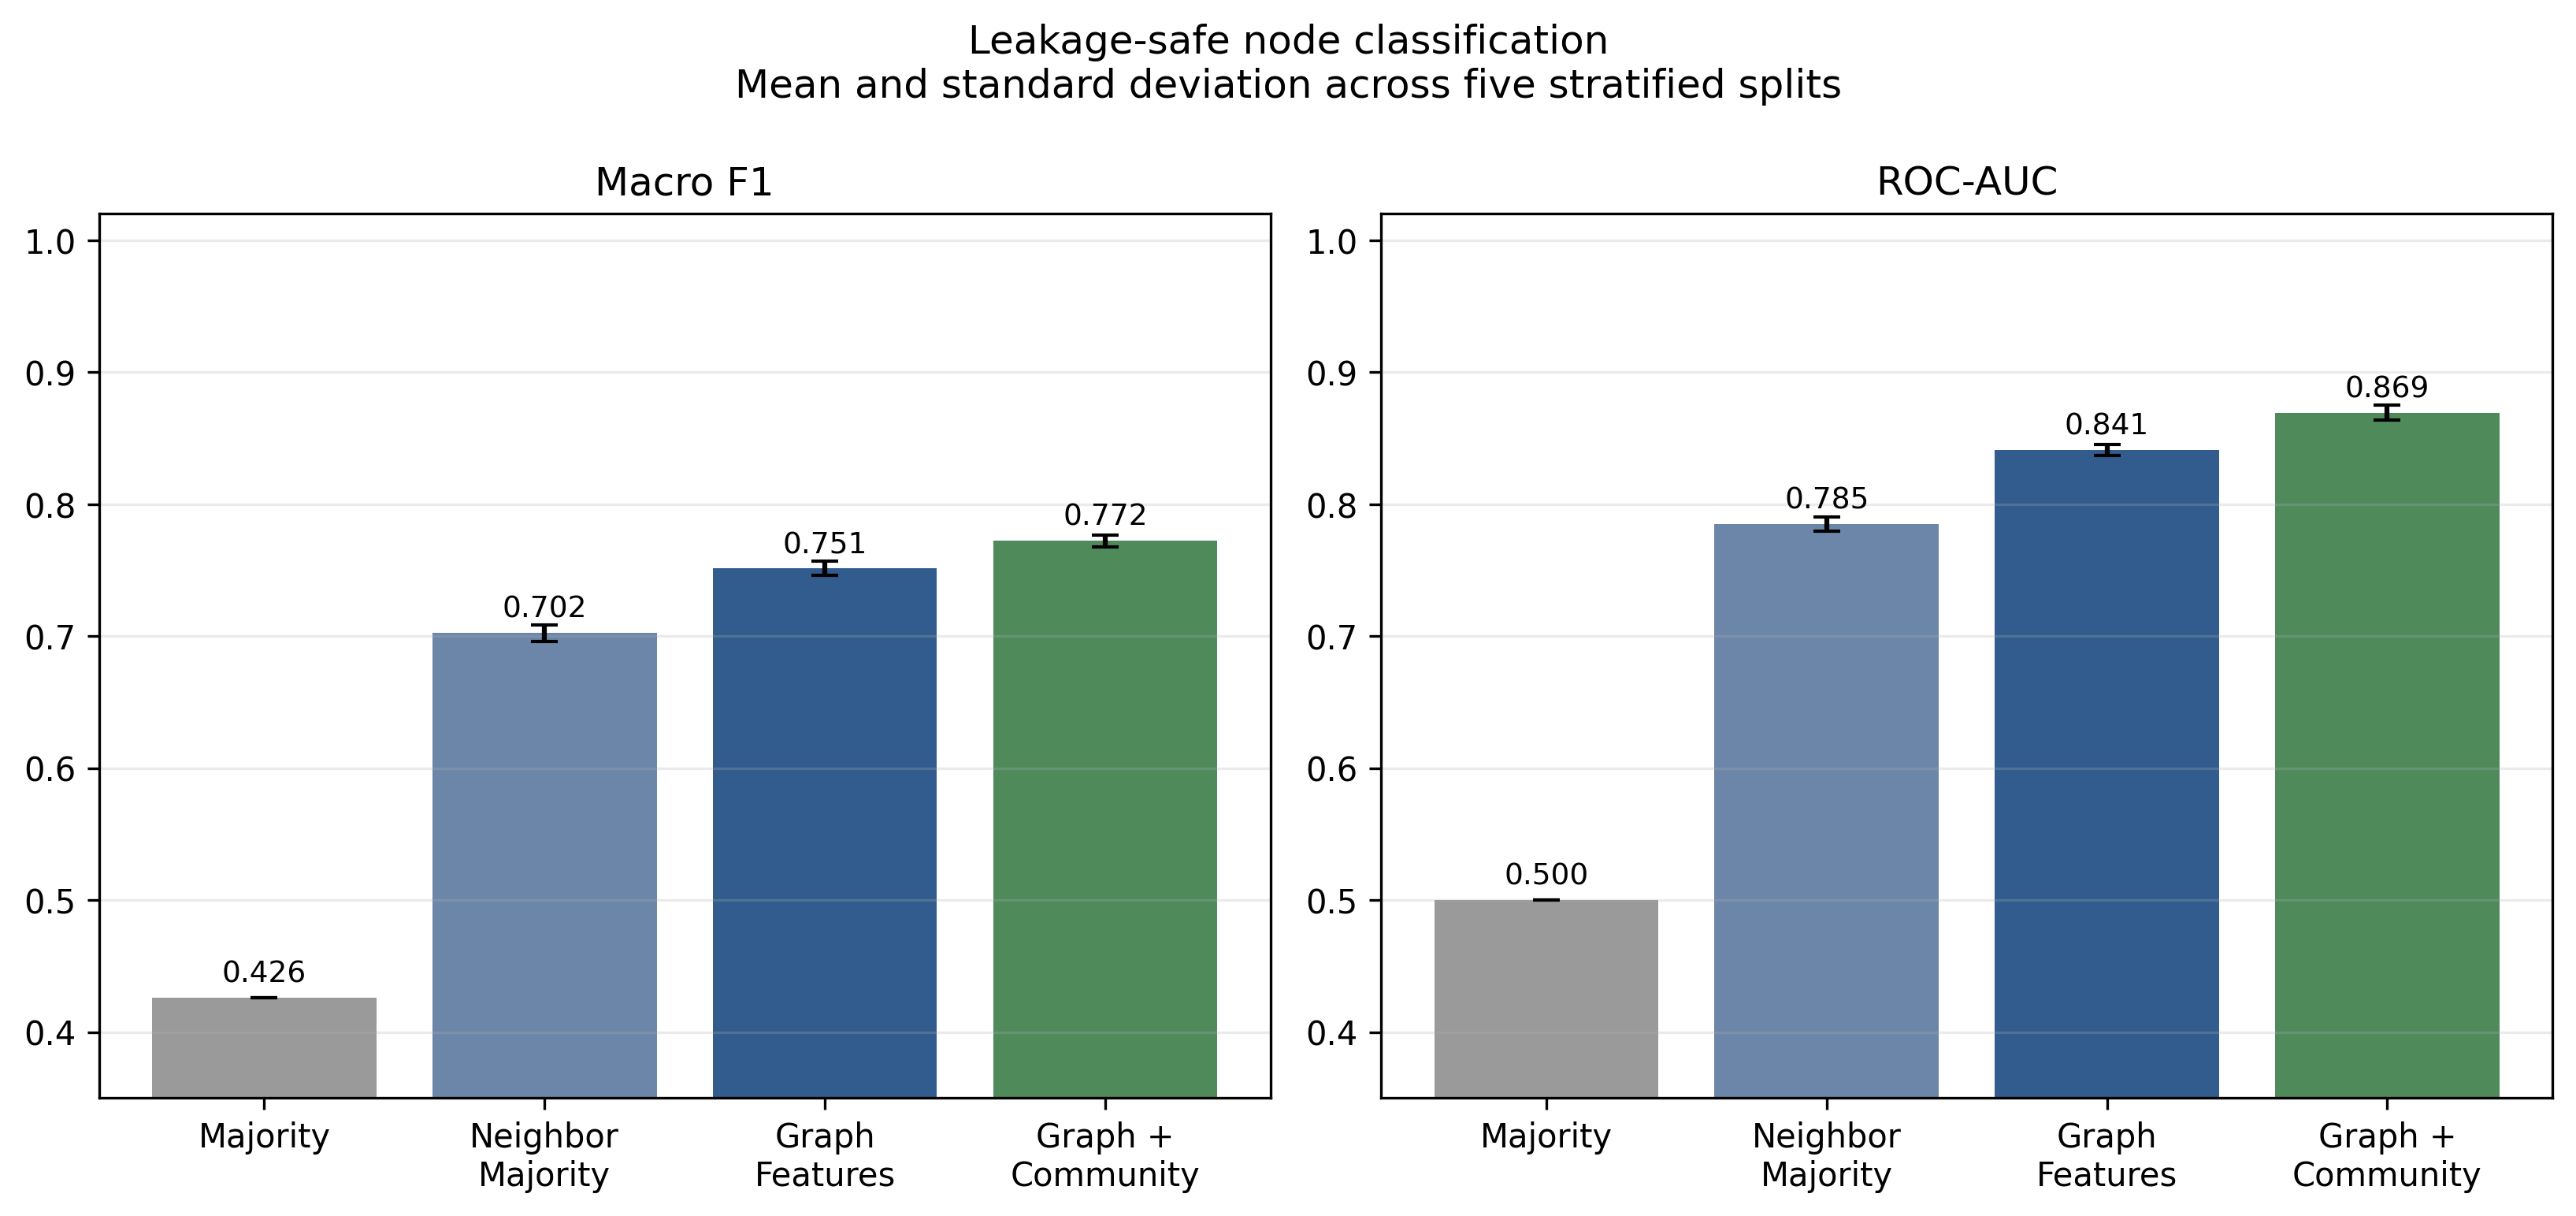

outputs/figures/threshold_tradeoff.png


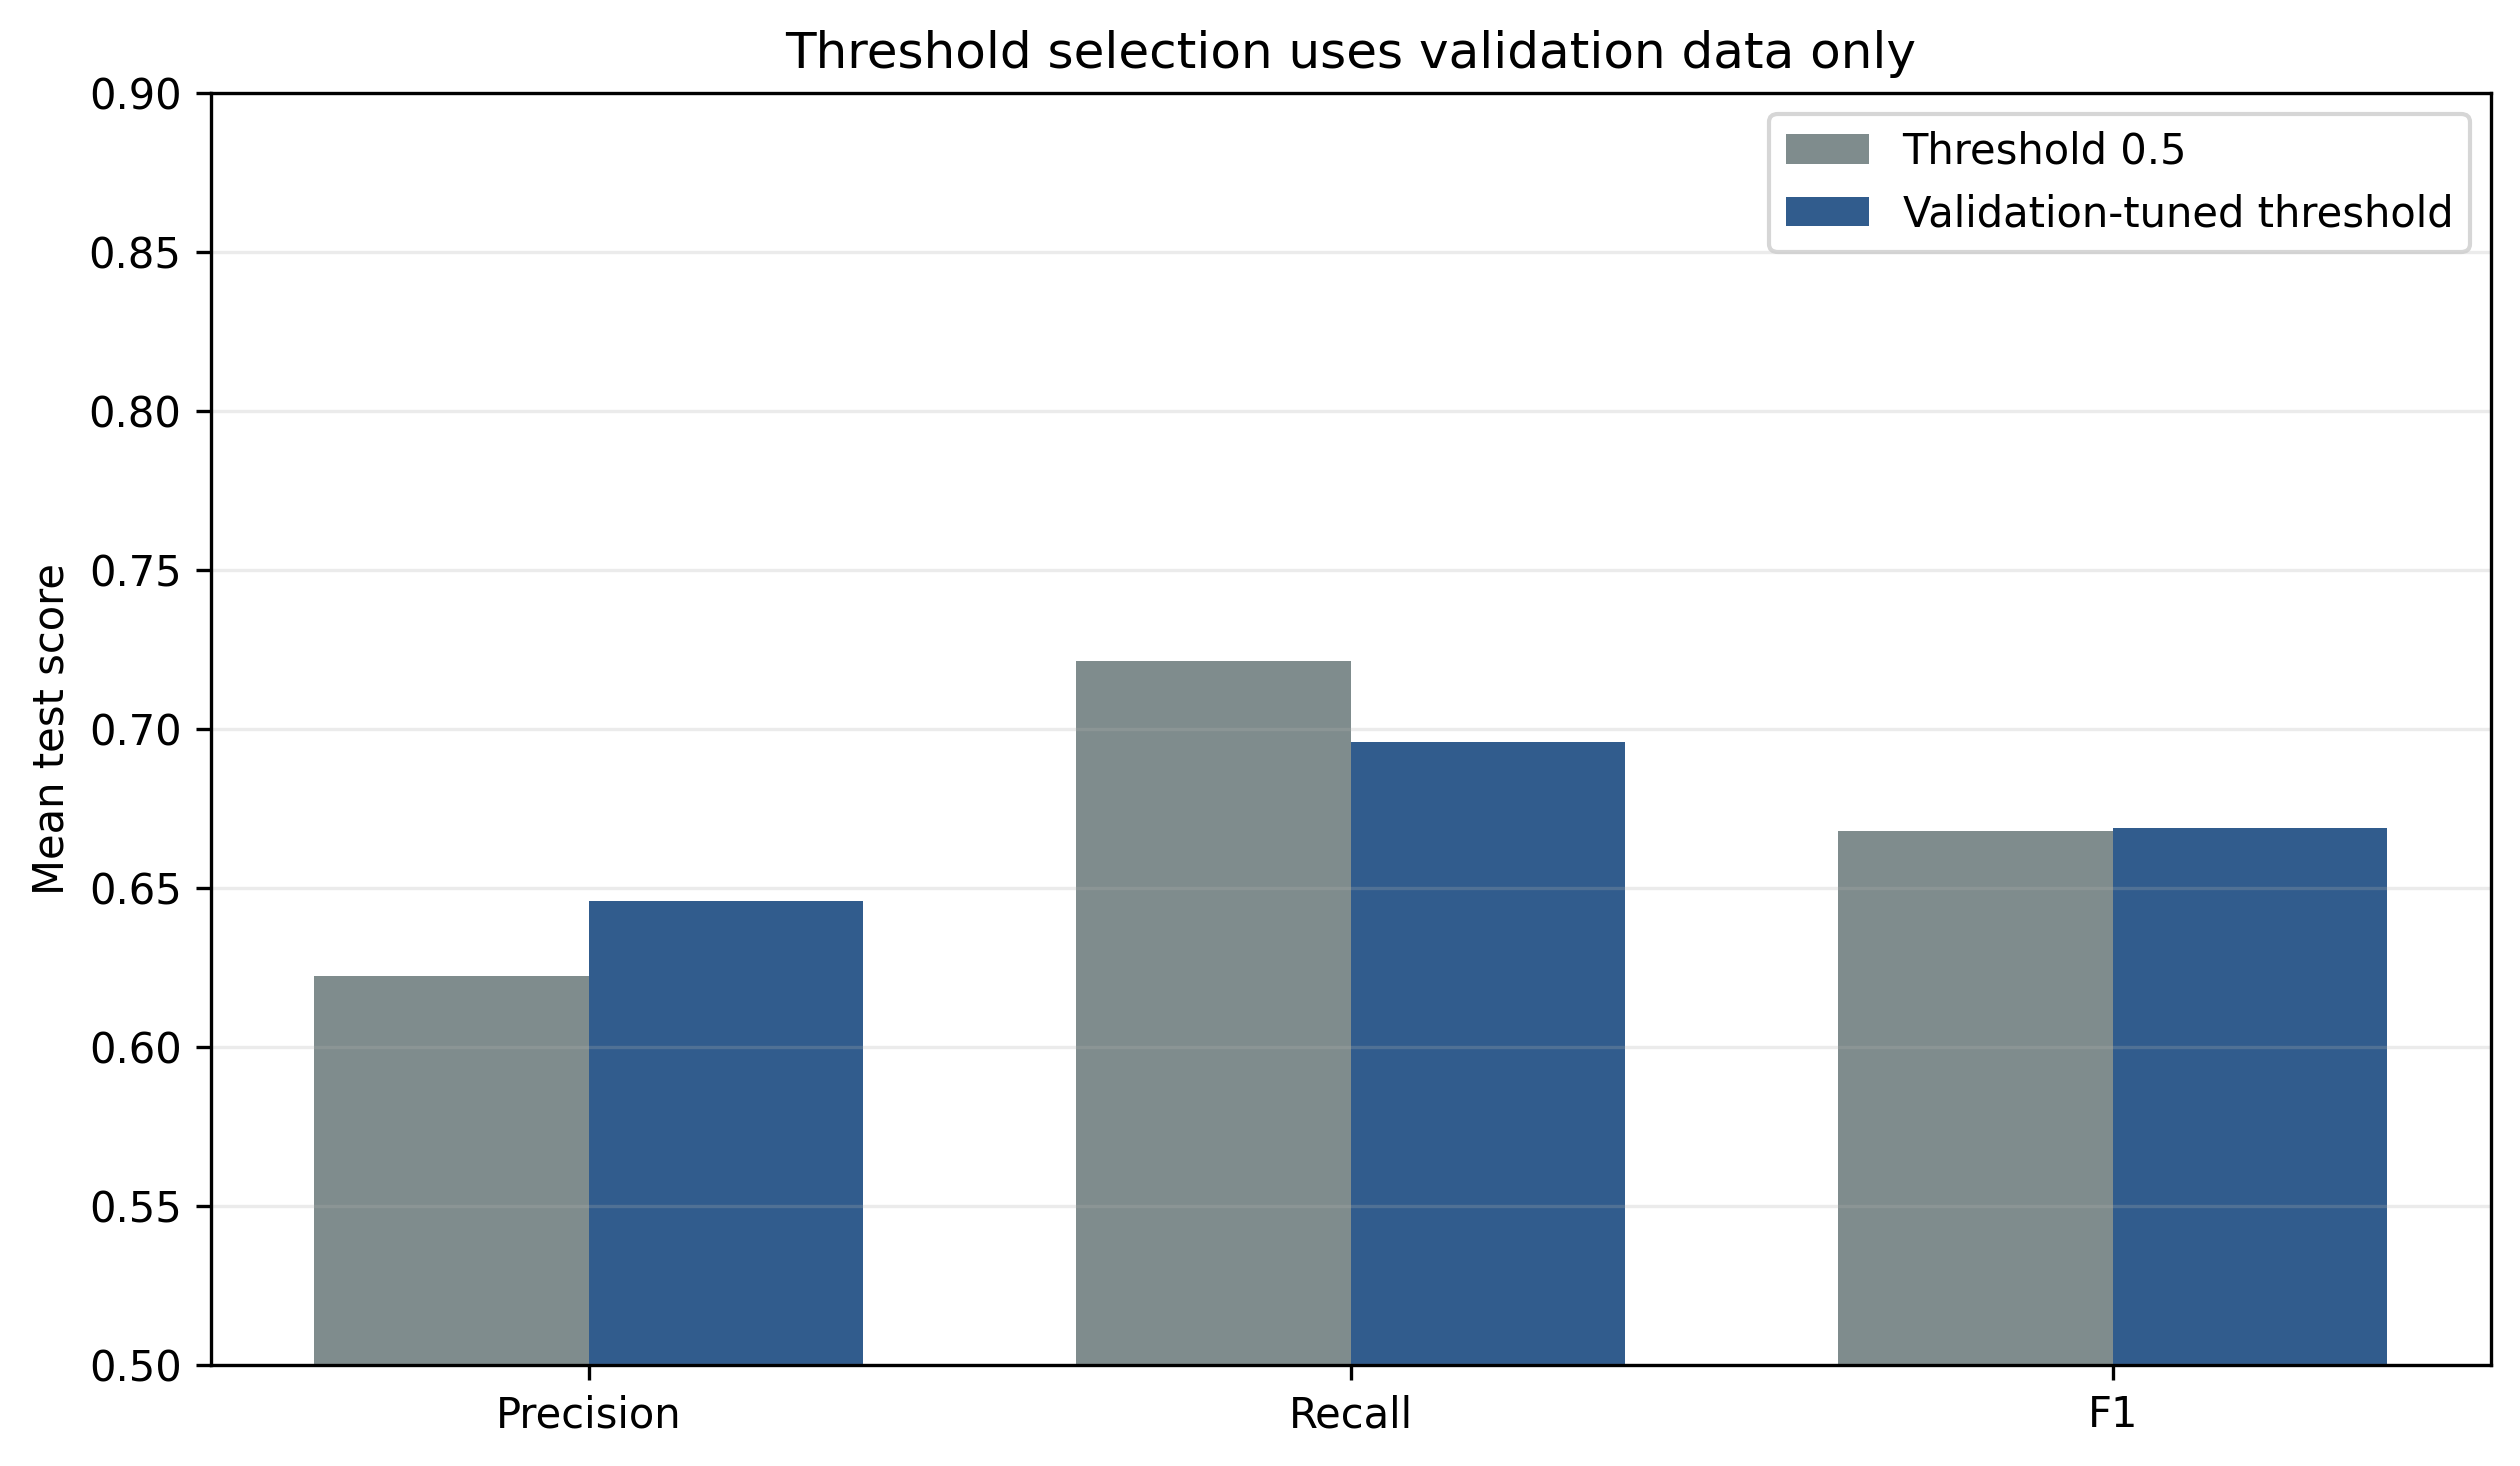

In [34]:
from IPython.display import Image, display
for relative_figure in [
    'outputs/figures/classification_comparison.png',
    'outputs/figures/threshold_tradeoff.png'
]:
    print(relative_figure)
    display(Image(filename=str(ROOT / relative_figure)))

**פלט, ממצאים ופרשנות.** תכונות קהילה משפרות באופן עקבי את המודל הידני. התרשים מדגיש מדוע יש להבחין בין יכולת דירוג (ROC-AUC) לבין החלטה בינארית תלויה-סף.

## סיכום המחברת

**מה בוצע.** מומשו ונבדקו ארבעה מודלי סיווג וכיוון סף נטול leakage.

**ממצאים מרכזיים.** מבנה הגרף מאפשר סיווג משמעותי; Graph+Community מוביל ב-baseline הידני עם ROC-AUC≈0.869.

**חיבור למחברת הבאה.** מחברת 06 בודקת אם embeddings ותוכן מוסיפים מידע מעבר לתכונות הידניות.